In [1]:
import pandas as pd

# Load the Excel file
file_path = './data/final_0903.xlsx'
data_df = pd.read_excel(file_path)  # 첫 번째 행을 건너뛰고 읽기

/source/ms/env/highlight/lib/python3.8/site-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


In [2]:
# 첫 번째 제공된 표에 기반한 매핑을 설정합니다.
type_mapping = {
    'A7B3': 'DP', 'AZ8F': 'Threshold', 'AX2N': 'Random',
    'BH5Z': 'DP', 'BZ7J': 'Threshold', 'BP1Y': 'Random',
    # 'CT4C': 'DP', 'CM6D': 'Threshold', 'CL9K': 'Random',
    'DE2R': 'DP', 'DZ6Q': 'Threshold', 'DE4K': 'Random',
    'ER8G': 'DP', 'EZ2L': 'Threshold', 'EJ1N': 'Random',
    'FA1N': 'DP', 'FZ3K': 'Threshold', 'FB7R': 'Random',

}


In [3]:

# 성별, 이름, 소요시간 열 이름 정의
gender_column = 'Q6'
name_column = 'Q1'
time_column = 'Duration (in seconds)'  # 소요 시간 열

# Extract the relevant parts of the column names and map them to the appropriate type (DP, Threshold, Random)
def clean_column_name(name):
    for key in type_mapping.keys():
        if key in name:
            return f"{key}_{name.split('_')[-1]}"  # 예를 들어 A7B3_1, A7B3_2 등을 만듭니다.
    return name

# Apply the cleaning function to all column names
data_df.columns = data_df.columns.map(clean_column_name)

# JSON 변환 함수 정의
def convert_to_json(row):
    question_data = {}
    
    for question_id, question_type in type_mapping.items():
        if question_id[0] not in question_data:
            question_data[question_id[0]] = {
                "Q1": {},
                "Q2": {},
                "Q3": {}
            }
        
        question_data[question_id[0]]["Q1"][question_type] = int(row.get(f'{question_id}_1', 0))
        question_data[question_id[0]]["Q2"][question_type] = int(row.get(f'{question_id}_2', 0))
        question_data[question_id[0]]["Q3"][question_type] = int(row.get(f'{question_id}_3', 0))
    
    return {
        "name": row.get(name_column, "Unknown"),
        "time": int(row.get(time_column, 0)) // 60,  # 소요시간을 분으로 변환
        "gender": row.get(gender_column, "Unknown"),
        "question": question_data
    }

# 모든 사람의 데이터를 JSON으로 변환
json_data_list = []
for _, row in data_df.iloc[1:].iterrows():  # 첫 번째 행은 열 이름이므로 두 번째 행부터 시작
    json_data_list.append(convert_to_json(row))




In [4]:
import json
import numpy as np
import pandas as pd
from scipy.stats import friedmanchisquare, wilcoxon
import matplotlib.pyplot as plt
import seaborn as sns

def calculate_average_scores(json_data_list):
    averaged_data = []
    for person in json_data_list:
        person_data = {'name': person['name']}
        for q in ['Q1', 'Q2', 'Q3']:
            dp_scores = []
            threshold_scores = []
            random_scores = []
            for dataset in ['A', 'B', 'D', 'E', 'F']:
                dp_scores.append(person['question'][dataset][q]['DP'])
                threshold_scores.append(person['question'][dataset][q]['Threshold'])
                random_scores.append(person['question'][dataset][q]['Random'])
            person_data[f'{q}_DP'] = np.mean(dp_scores)
            person_data[f'{q}_Threshold'] = np.mean(threshold_scores)
            person_data[f'{q}_Random'] = np.mean(random_scores)
        averaged_data.append(person_data)
    return pd.DataFrame(averaged_data)

def perform_friedman_test(data, question):
    dp = data[f'{question}_DP']
    threshold = data[f'{question}_Threshold']
    random = data[f'{question}_Random']
    
    statistic, p_value = friedmanchisquare(dp, threshold, random)
    
    return statistic, p_value

def perform_wilcoxon_tests(data, question):
    dp = data[f'{question}_DP']
    threshold = data[f'{question}_Threshold']
    random = data[f'{question}_Random']
    
    # Perform Wilcoxon signed-rank test for each pair
    z_dp_threshold, p_dp_threshold = wilcoxon(dp, threshold)
    z_dp_random, p_dp_random = wilcoxon(dp, random)
    z_threshold_random, p_threshold_random = wilcoxon(threshold, random)
    
    # Collect p-values and apply Holm-Bonferroni correction
    p_values = [p_dp_threshold, p_dp_random, p_threshold_random]
    comparisons = ['DP vs Threshold', 'DP vs Random', 'Threshold vs Random']
    
    # Sort p-values and their corresponding comparison names
    sorted_p_values = sorted(zip(p_values, comparisons), key=lambda x: x[0])
    sorted_p_values, sorted_comparisons = zip(*sorted_p_values)

    # Apply Holm-Bonferroni correction
    n_comparisons = len(sorted_p_values)
    corrected_p_values = []
    for i, p in enumerate(sorted_p_values):
        corrected_p = min(p * (n_comparisons - i), 1)  # Apply Holm-Bonferroni correction
        corrected_p_values.append(corrected_p)
    
    # Return the z-values and Holm-Bonferroni corrected p-values
    return (z_dp_threshold, corrected_p_values[sorted_comparisons.index('DP vs Threshold')]), \
           (z_dp_random, corrected_p_values[sorted_comparisons.index('DP vs Random')]), \
           (z_threshold_random, corrected_p_values[sorted_comparisons.index('Threshold vs Random')])


def plot_p_value_matrix(p_values, question):
    matrix = np.array([
        [np.nan, p_values[0], p_values[1]],
        [p_values[0], np.nan, p_values[2]],
        [p_values[1], p_values[2], np.nan]
    ])
    
    plt.figure(figsize=(8, 6))
    sns.heatmap(matrix, annot=True, fmt=".4f", cmap='coolwarm', center=0.05,
                xticklabels=['DP', 'Threshold', 'Random'],
                yticklabels=['DP', 'Threshold', 'Random'])
    plt.title(f'P-value Matrix for {question} (Wilcoxon signed-rank tests)')
    plt.show()


In [5]:
import json
output_file_path = 'output_json_data_list.json'

with open(output_file_path, 'w', encoding='utf-8') as f:
    json.dump(json_data_list, f, ensure_ascii=False, indent=4)

In [6]:
import json
import matplotlib.pyplot as plt
import numpy as np

# JSON 파일 불러오기

with open(output_file_path, 'r', encoding='utf-8') as f:
    json_data_list = json.load(f)


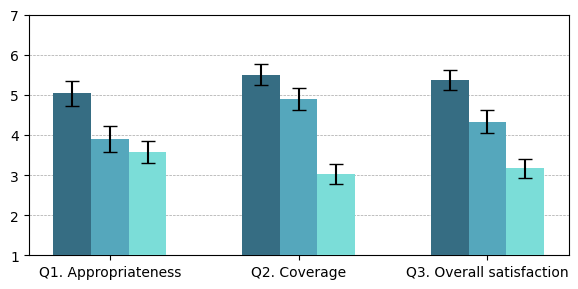

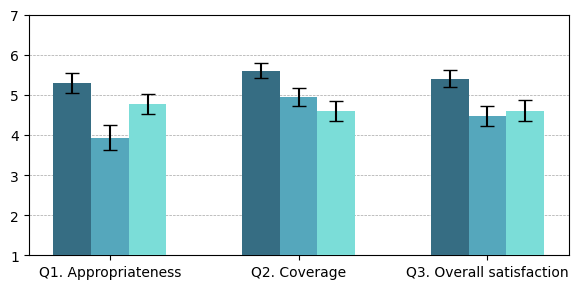

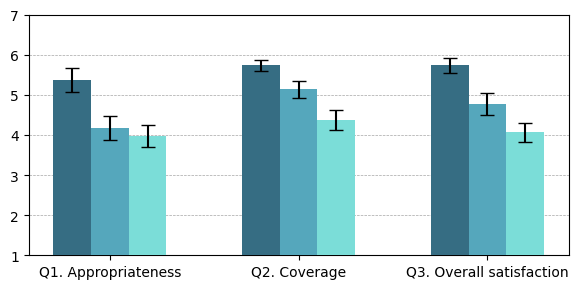

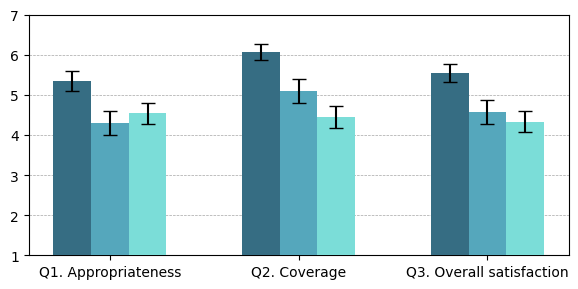

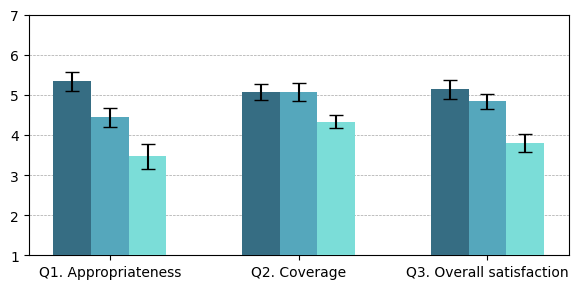

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 각 사람의 DP, Threshold, Random 점수를 3개의 질문에 대해 계산하는 함수
def calculate_individual_scores_across_questions(json_data_list, dataset_id):
    dp_scores, threshold_scores, random_scores = [], [], []
    
    for data in json_data_list:
        dp_vals, threshold_vals, random_vals = [], [], []
        
        for question_number in range(1, 4):
            question_data = data['question'][dataset_id][f"Q{question_number}"]
            dp_vals.append(question_data['DP'])
            threshold_vals.append(question_data['Threshold'])
            random_vals.append(question_data['Random'])
        
        dp_scores.append(dp_vals)
        threshold_scores.append(threshold_vals)
        random_scores.append(random_vals)
    
    return np.array(dp_scores), np.array(threshold_scores), np.array(random_scores)





def plot_scores_by_dataset():
    # Mapping datasets to descriptive names
    dataset_labels = {
        'A': 'Golf',
        'B': 'Entertainment',
        'D': 'Tennis',
        'E': 'Soccer',
        'F': 'Documentary'
    }
    questions = ['Q1. Appropriateness', 'Q2. Coverage', 'Q3. Overall satisfaction']
    x = np.arange(len(questions))
    width = 0.2

    for dataset_id, dataset_name in dataset_labels.items():
        dp_scores, threshold_scores, random_scores = calculate_individual_scores_across_questions(json_data_list, dataset_id)
        
        # Calculate means and SEMs for each question within the dataset
        dp_means = np.mean(dp_scores, axis=0)
        dp_sems = np.std(dp_scores, axis=0, ddof=1) / np.sqrt(dp_scores.shape[0])
        
        threshold_means = np.mean(threshold_scores, axis=0)
        threshold_sems = np.std(threshold_scores, axis=0, ddof=1) / np.sqrt(threshold_scores.shape[0])
        
        random_means = np.mean(random_scores, axis=0)
        random_sems = np.std(random_scores, axis=0, ddof=1) / np.sqrt(random_scores.shape[0])
        
        # Plotting for each dataset across questions
        fig, ax = plt.subplots(figsize=(6, 3))
        
        ax.set_ylim(1, 7)
        ax.grid(True, axis='y', color='gray', linestyle='--', linewidth=0.5, alpha=0.7, zorder=0)

        ax.bar(x - width, dp_means, width, yerr=dp_sems, capsize=5, label='DP', color='#366D83', zorder=3)
        ax.bar(x, threshold_means, width, yerr=threshold_sems, capsize=5, label='Threshold',  color='#55A7BC', zorder=3)
        ax.bar(x + width, random_means, width, yerr=random_sems, capsize=5, label='Random', color='#7BDDD8', zorder=3)
        
        ax.set_xticks(x)
        ax.set_xticklabels(questions)
        ax.set_title(f'{dataset_name}')
        # ax.set_ylabel('Score')
        # ax.legend()
        
        plt.tight_layout()
        plt.show()

# 각 dataset 별 question에 대한 점수 그래프 그리기
plot_scores_by_dataset()

In [ ]:
# 각 사람의 DP, Threshold, Random 평균을 계산하는 함수
def calculate_individual_averages(json_data_list, question_number):
    dp_averages = []
    threshold_averages = []
    random_averages = []
    
    for data in json_data_list:
        dp_values = []
        threshold_values = []
        random_values = []
        
        for key in ['A', 'B', 'F', 'D', 'E']:
            question_data = data['question'][key][f"Q{question_number}"]
            dp_values.append(question_data['DP'])
            threshold_values.append(question_data['Threshold'])
            random_values.append(question_data['Random'])
        
        dp_averages.append(np.mean(dp_values))
        threshold_averages.append(np.mean(threshold_values))
        random_averages.append(np.mean(random_values))
    
    return dp_averages, threshold_averages, random_averages


In [23]:
def calculate_scores(json_data_list, dataset):
    data = []
    for person in json_data_list:
        person_data = {'name': person['name']}
        for q in ['Q1', 'Q2', 'Q3']:
            person_data[f'{q}_DP'] = person['question'][dataset][q]['DP']
            person_data[f'{q}_Threshold'] = person['question'][dataset][q]['Threshold']
            person_data[f'{q}_Random'] = person['question'][dataset][q]['Random']
        data.append(person_data)
    return pd.DataFrame(data)

In [30]:

def add_aster(p):
    if 0.01 < p < 0.05:
        return "*"
    elif 0.001 < p < 0.01:
        return "**"
    elif p < 0.001:
        return '***'
    else:
        return "NO RELATION"

for dataset in ['A', 'B', 'D', 'E', 'F']:
    print(f"=================={dataset}==============")
    data = calculate_scores(json_data_list, dataset)

    # 각 질문에 대해 프리드만 검정 수행 후 Wilcoxon 사후 검정
    # 각 질문에 대해 프리드만 검정 수행 후 Wilcoxon 사후 검정
    for question in ['Q1', 'Q2', 'Q3']:
        statistic, p_value = perform_friedman_test(data, question)
        
        print(f"\n{question}:")
        print(f"Friedman statistic: {statistic}")
        print(f"Friedman p-value: {p_value}")
        
        if p_value < 0.05:
            print("Significant difference found. Performing Wilcoxon signed-rank tests:")
            (z_dp_threshold, p_dp_threshold), (z_dp_random, p_dp_random), (z_threshold_random, p_threshold_random) = perform_wilcoxon_tests(data, question)
            
            print(f"DP vs Threshold: z = {z_dp_threshold:.4f}, p = {p_dp_threshold:.10f}, {add_aster(p_dp_threshold)}")
            print(f"DP vs Random: z = {z_dp_random:.4f}, p = {p_dp_random:.10f}, {add_aster(p_dp_random)}")
            print(f"Threshold vs Random: z = {z_threshold_random:.4f}, p = {p_threshold_random:.10f}, {add_aster(p_threshold_random)}")
            
            # plot_p_value_matrix([p_dp_threshold, p_dp_random, p_threshold_random], question)
        else:
            print("No significant difference found, post-hoc analysis not performed")

==================A==============

Q1:
Friedman statistic: 24.35164835164832
Friedman p-value: 5.153553012499748e-06
Significant difference found. Performing Wilcoxon signed-rank tests:
DP vs Threshold: z = 24.0000, p = 0.0014764670, **
DP vs Random: z = 5.5000, p = 0.0002073884, ***
Threshold vs Random: z = 71.0000, p = 0.1905672028, NO RELATION

Q2:
Friedman statistic: 37.940000000000005
Friedman p-value: 5.773426991878885e-09
Significant difference found. Performing Wilcoxon signed-rank tests:
DP vs Threshold: z = 47.5000, p = 0.0140439063, *
DP vs Random: z = 0.0000, p = 0.0000222043, ***
Threshold vs Random: z = 3.5000, p = 0.0000479002, ***

Q3:
Friedman statistic: 33.13461538461535
Friedman p-value: 6.381307742366505e-08
Significant difference found. Performing Wilcoxon signed-rank tests:
DP vs Threshold: z = 19.5000, p = 0.0007684882, ***
DP vs Random: z = 4.5000, p = 0.0000158543, ***
Threshold vs Random: z = 40.0000, p = 0.0008121150, ***
==================B==============

Q1

In [33]:
data = calculate_scores(json_data_list, 'A')
data

,name,Q1_DP,Q1_Threshold,Q1_Random,Q2_DP,Q2_Threshold,Q2_Random,Q3_DP,Q3_Threshold,Q3_Random
0,김태연,7,5,5,7,3,2,7,3,2
1,이지수,6,2,3,6,4,2,6,3,3
2,백인호,7,7,6,6,6,5,5,3,4
3,이준혁,7,5,5,7,6,6,7,5,5
4,임영민,7,5,3,7,5,2,7,5,3
5,송준호,3,2,2,5,5,5,3,3,2
6,이은교,4,3,3,4,3,3,4,4,3
7,양민우,6,5,4,6,6,4,6,5,4
8,박신우,3,2,2,3,2,2,3,2,2
9,김해성,5,2,2,5,5,3,5,3,2


In [ ]:
data

In [ ]:
import pandas as pd

# Load the Excel file
file_path = './data/final_0903.xlsx'
data_df = pd.read_excel(file_path)  # 첫 번째 행을 건너뛰고 읽기

/source/ms/env/highlight/lib/python3.8/site-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


In [ ]:
# 첫 번째 제공된 표에 기반한 매핑을 설정합니다.
type_mapping = {
    'A7B3': 'DP', 'AZ8F': 'Threshold', 'AX2N': 'Random',
    'BH5Z': 'DP', 'BZ7J': 'Threshold', 'BP1Y': 'Random',
    # 'CT4C': 'DP', 'CM6D': 'Threshold', 'CL9K': 'Random',
    'DE2R': 'DP', 'DZ6Q': 'Threshold', 'DE4K': 'Random',
    'ER8G': 'DP', 'EZ2L': 'Threshold', 'EJ1N': 'Random',
    'FA1N': 'DP', 'FZ3K': 'Threshold', 'FB7R': 'Random',

}


In [ ]:

# 성별, 이름, 소요시간 열 이름 정의
gender_column = 'Q6'
name_column = 'Q1'
time_column = 'Duration (in seconds)'  # 소요 시간 열

# Extract the relevant parts of the column names and map them to the appropriate type (DP, Threshold, Random)
def clean_column_name(name):
    for key in type_mapping.keys():
        if key in name:
            return f"{key}_{name.split('_')[-1]}"  # 예를 들어 A7B3_1, A7B3_2 등을 만듭니다.
    return name

# Apply the cleaning function to all column names
data_df.columns = data_df.columns.map(clean_column_name)

# JSON 변환 함수 정의
def convert_to_json(row):
    question_data = {}
    
    for question_id, question_type in type_mapping.items():
        if question_id[0] not in question_data:
            question_data[question_id[0]] = {
                "Q1": {},
                "Q2": {},
                "Q3": {}
            }
        
        question_data[question_id[0]]["Q1"][question_type] = int(row.get(f'{question_id}_1', 0))
        question_data[question_id[0]]["Q2"][question_type] = int(row.get(f'{question_id}_2', 0))
        question_data[question_id[0]]["Q3"][question_type] = int(row.get(f'{question_id}_3', 0))
    
    return {
        "name": row.get(name_column, "Unknown"),
        "time": int(row.get(time_column, 0)) // 60,  # 소요시간을 분으로 변환
        "gender": row.get(gender_column, "Unknown"),
        "question": question_data
    }

# 모든 사람의 데이터를 JSON으로 변환
json_data_list = []
for _, row in data_df.iloc[1:].iterrows():  # 첫 번째 행은 열 이름이므로 두 번째 행부터 시작
    json_data_list.append(convert_to_json(row))




In [ ]:
import json
import numpy as np
import pandas as pd
from scipy.stats import friedmanchisquare, wilcoxon
import matplotlib.pyplot as plt
import seaborn as sns

def calculate_average_scores(json_data_list):
    averaged_data = []
    for person in json_data_list:
        person_data = {'name': person['name']}
        for q in ['Q1', 'Q2', 'Q3']:
            dp_scores = []
            threshold_scores = []
            random_scores = []
            for dataset in ['A', 'B', 'D', 'E', 'F']:
                dp_scores.append(person['question'][dataset][q]['DP'])
                threshold_scores.append(person['question'][dataset][q]['Threshold'])
                random_scores.append(person['question'][dataset][q]['Random'])
            person_data[f'{q}_DP'] = np.mean(dp_scores)
            person_data[f'{q}_Threshold'] = np.mean(threshold_scores)
            person_data[f'{q}_Random'] = np.mean(random_scores)
        averaged_data.append(person_data)
    return pd.DataFrame(averaged_data)

def perform_friedman_test(data, question):
    dp = data[f'{question}_DP']
    threshold = data[f'{question}_Threshold']
    random = data[f'{question}_Random']
    
    statistic, p_value = friedmanchisquare(dp, threshold, random)
    
    return statistic, p_value

def perform_wilcoxon_tests(data, question):
    dp = data[f'{question}_DP']
    threshold = data[f'{question}_Threshold']
    random = data[f'{question}_Random']
    
    # Perform Wilcoxon signed-rank test for each pair
    z_dp_threshold, p_dp_threshold = wilcoxon(dp, threshold)
    z_dp_random, p_dp_random = wilcoxon(dp, random)
    z_threshold_random, p_threshold_random = wilcoxon(threshold, random)
    
    # Collect p-values and apply Holm-Bonferroni correction
    p_values = [p_dp_threshold, p_dp_random, p_threshold_random]
    comparisons = ['DP vs Threshold', 'DP vs Random', 'Threshold vs Random']
    
    # Sort p-values and their corresponding comparison names
    sorted_p_values = sorted(zip(p_values, comparisons), key=lambda x: x[0])
    sorted_p_values, sorted_comparisons = zip(*sorted_p_values)

    # Apply Holm-Bonferroni correction
    n_comparisons = len(sorted_p_values)
    corrected_p_values = []
    for i, p in enumerate(sorted_p_values):
        corrected_p = min(p * (n_comparisons - i), 1)  # Apply Holm-Bonferroni correction
        corrected_p_values.append(corrected_p)
    
    # Return the z-values and Holm-Bonferroni corrected p-values
    return (z_dp_threshold, corrected_p_values[sorted_comparisons.index('DP vs Threshold')]), \
           (z_dp_random, corrected_p_values[sorted_comparisons.index('DP vs Random')]), \
           (z_threshold_random, corrected_p_values[sorted_comparisons.index('Threshold vs Random')])


def plot_p_value_matrix(p_values, question):
    matrix = np.array([
        [np.nan, p_values[0], p_values[1]],
        [p_values[0], np.nan, p_values[2]],
        [p_values[1], p_values[2], np.nan]
    ])
    
    plt.figure(figsize=(8, 6))
    sns.heatmap(matrix, annot=True, fmt=".4f", cmap='coolwarm', center=0.05,
                xticklabels=['DP', 'Threshold', 'Random'],
                yticklabels=['DP', 'Threshold', 'Random'])
    plt.title(f'P-value Matrix for {question} (Wilcoxon signed-rank tests)')
    plt.show()


In [ ]:
import json
output_file_path = 'output_json_data_list.json'

with open(output_file_path, 'w', encoding='utf-8') as f:
    json.dump(json_data_list, f, ensure_ascii=False, indent=4)

In [ ]:
import json
import matplotlib.pyplot as plt
import numpy as np

# JSON 파일 불러오기

with open(output_file_path, 'r', encoding='utf-8') as f:
    json_data_list = json.load(f)


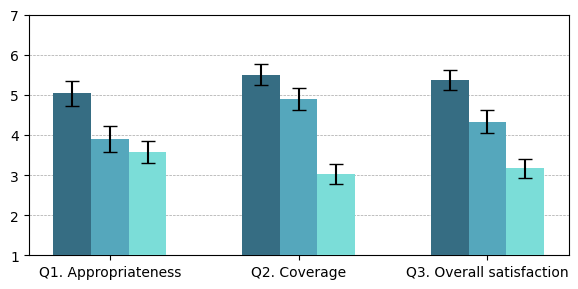

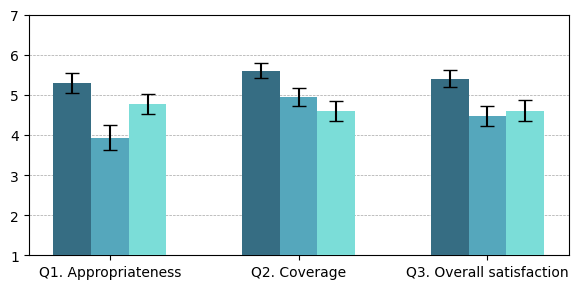

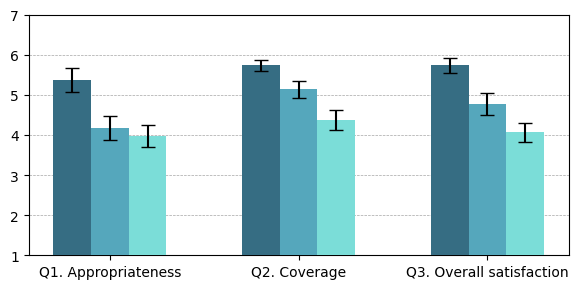

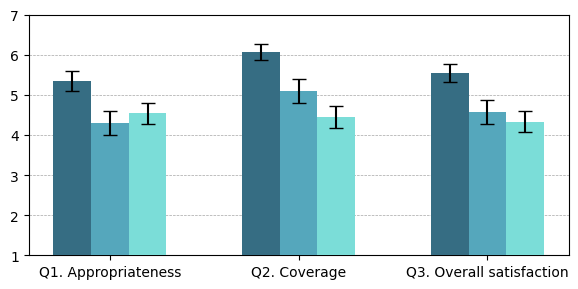

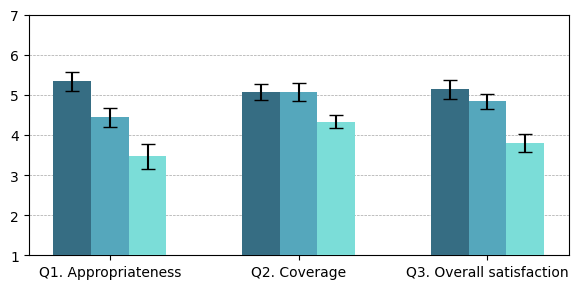

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 각 사람의 DP, Threshold, Random 점수를 3개의 질문에 대해 계산하는 함수
def calculate_individual_scores_across_questions(json_data_list, dataset_id):
    dp_scores, threshold_scores, random_scores = [], [], []
    
    for data in json_data_list:
        dp_vals, threshold_vals, random_vals = [], [], []
        
        for question_number in range(1, 4):
            question_data = data['question'][dataset_id][f"Q{question_number}"]
            dp_vals.append(question_data['DP'])
            threshold_vals.append(question_data['Threshold'])
            random_vals.append(question_data['Random'])
        
        dp_scores.append(dp_vals)
        threshold_scores.append(threshold_vals)
        random_scores.append(random_vals)
    
    return np.array(dp_scores), np.array(threshold_scores), np.array(random_scores)





def plot_scores_by_dataset():
    # Mapping datasets to descriptive names
    dataset_labels = {
        'A': 'Golf',
        'B': 'Entertainment',
        'D': 'Tennis',
        'E': 'Soccer',
        'F': 'Documentary'
    }
    questions = ['Q1. Appropriateness', 'Q2. Coverage', 'Q3. Overall satisfaction']
    x = np.arange(len(questions))
    width = 0.2

    for dataset_id, dataset_name in dataset_labels.items():
        dp_scores, threshold_scores, random_scores = calculate_individual_scores_across_questions(json_data_list, dataset_id)
        
        # Calculate means and SEMs for each question within the dataset
        dp_means = np.mean(dp_scores, axis=0)
        dp_sems = np.std(dp_scores, axis=0, ddof=1) / np.sqrt(dp_scores.shape[0])
        
        threshold_means = np.mean(threshold_scores, axis=0)
        threshold_sems = np.std(threshold_scores, axis=0, ddof=1) / np.sqrt(threshold_scores.shape[0])
        
        random_means = np.mean(random_scores, axis=0)
        random_sems = np.std(random_scores, axis=0, ddof=1) / np.sqrt(random_scores.shape[0])
        
        # Plotting for each dataset across questions
        fig, ax = plt.subplots(figsize=(6, 3))
        
        ax.set_ylim(1, 7)
        ax.grid(True, axis='y', color='gray', linestyle='--', linewidth=0.5, alpha=0.7, zorder=0)

        ax.bar(x - width, dp_means, width, yerr=dp_sems, capsize=5, label='DP', color='#366D83', zorder=3)
        ax.bar(x, threshold_means, width, yerr=threshold_sems, capsize=5, label='Threshold',  color='#55A7BC', zorder=3)
        ax.bar(x + width, random_means, width, yerr=random_sems, capsize=5, label='Random', color='#7BDDD8', zorder=3)
        
        ax.set_xticks(x)
        ax.set_xticklabels(questions)
        ax.set_title(f'{dataset_name}')
        # ax.set_ylabel('Score')
        # ax.legend()
        
        plt.tight_layout()
        plt.show()

# 각 dataset 별 question에 대한 점수 그래프 그리기
plot_scores_by_dataset()

In [ ]:
# 각 사람의 DP, Threshold, Random 평균을 계산하는 함수
def calculate_individual_averages(json_data_list, question_number):
    dp_averages = []
    threshold_averages = []
    random_averages = []
    
    for data in json_data_list:
        dp_values = []
        threshold_values = []
        random_values = []
        
        for key in ['A', 'B', 'F', 'D', 'E']:
            question_data = data['question'][key][f"Q{question_number}"]
            dp_values.append(question_data['DP'])
            threshold_values.append(question_data['Threshold'])
            random_values.append(question_data['Random'])
        
        dp_averages.append(np.mean(dp_values))
        threshold_averages.append(np.mean(threshold_values))
        random_averages.append(np.mean(random_values))
    
    return dp_averages, threshold_averages, random_averages


[5.2733333333333325, 5.593333333333333, 5.433333333333333] [4.1466666666666665, 5.026666666666667, 4.593333333333334] [4.06, 4.153333333333333, 3.9933333333333336]


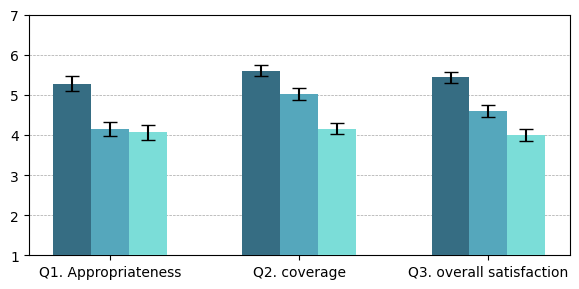

In [ ]:
def plot_combined_question_data():
    dp_means, threshold_means, random_means = [], [], []
    dp_sems, threshold_sems, random_sems = [], [], []

    for i in range(1, 4):
        dp, threshold, random = calculate_individual_averages(json_data_list, i)
        dp_means.append(dp)
        threshold_means.append(threshold)
        random_means.append(random)
        
        # # 표준 오차 계산 (SEM = 표준편차 / sqrt(샘플 수))
        # n = len(json_data_list)
        # dp_sems.append(dp_stats[1] / np.sqrt(n))
        # threshold_sems.append(threshold_stats[1] / np.sqrt(n))
        # random_sems.append(random_stats[1] / np.sqrt(n))
    def calculate_mean_and_sem(data):
        means = [np.mean(question) for question in data]
        sems = [np.std(question, ddof=1) / np.sqrt(len(question)) for question in data]
        return means, sems

    dp_avg, dp_sem = calculate_mean_and_sem(dp_means)
    threshold_avg, threshold_sem = calculate_mean_and_sem(threshold_means)
    random_avg, random_sem = calculate_mean_and_sem(random_means)
    
        # 그래프 생성
    labels = ['Q1. Appropriateness', 'Q2. coverage', 'Q3. overall satisfaction']
    x = np.arange(len(labels))
    width = 0.2
    fig, ax = plt.subplots(figsize=(6, 3))
    
    # grid 설정
    ax.set_ylim(1, 7)
    ax.grid(True, axis='y', color='gray', linestyle='--', linewidth=0.5, alpha=0.7, zorder=0)
    
    # 각각의 막대 그래프 (오차 막대 포함)
    ax.bar(x - width, dp_avg, width, yerr=dp_sem, capsize=5, color='#366D83', label='DP', zorder=3)
    ax.bar(x, threshold_avg, width, yerr=threshold_sem, capsize=5, color='#55A7BC', label='Threshold', zorder=3)
    ax.bar(x + width, random_avg, width, yerr=random_sem, capsize=5, color='#7BDDD8', label='Random', zorder=3)
    print(dp_avg, threshold_avg, random_avg)
    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    # ax.legend()
    
    plt.tight_layout()
    plt.show()


# 그래프 그리기
plot_combined_question_data()


In [ ]:

# 데이터 준비
averaged_data = calculate_average_scores(json_data_list)

# 각 질문에 대해 프리드만 검정 수행 후 Wilcoxon 사후 검정
# 각 질문에 대해 프리드만 검정 수행 후 Wilcoxon 사후 검정
for question in ['Q1', 'Q2', 'Q3']:
    statistic, p_value = perform_friedman_test(averaged_data, question)
    
    print(f"\n{question}:")
    print(f"Friedman statistic: {statistic}")
    print(f"Friedman p-value: {p_value}")
    
    if p_value < 0.05:
        print("Significant difference found. Performing Wilcoxon signed-rank tests:")
        (z_dp_threshold, p_dp_threshold), (z_dp_random, p_dp_random), (z_threshold_random, p_threshold_random) = perform_wilcoxon_tests(averaged_data, question)
        
        print(f"DP vs Threshold: z = {z_dp_threshold:.4f}, p = {p_dp_threshold:.10f}")
        print(f"DP vs Random: z = {z_dp_random:.4f}, p = {p_dp_random:.10f}")
        print(f"Threshold vs Random: z = {z_threshold_random:.4f}, p = {p_threshold_random:.10f}")
        
        # plot_p_value_matrix([p_dp_threshold, p_dp_random, p_threshold_random], question)
    else:
        print("No significant difference found, post-hoc analysis not performed")


Q1:
Friedman statistic: 38.991150442477846
Friedman p-value: 3.413337718664741e-09
Significant difference found. Performing Wilcoxon signed-rank tests:
DP vs Threshold: z = 4.0000, p = 0.0000115828
DP vs Random: z = 0.0000, p = 0.0000109962
Threshold vs Random: z = 163.0000, p = 0.5319343136

Q2:
Friedman statistic: 42.939130434782584
Friedman p-value: 4.741178400687421e-10
Significant difference found. Performing Wilcoxon signed-rank tests:
DP vs Threshold: z = 19.5000, p = 0.0001163834
DP vs Random: z = 0.0000, p = 0.0000000056
Threshold vs Random: z = 21.0000, p = 0.0000016652

Q3:
Friedman statistic: 40.92173913043475
Friedman p-value: 1.3000416101059152e-09
Significant difference found. Performing Wilcoxon signed-rank tests:
DP vs Threshold: z = 14.0000, p = 0.0000803130
DP vs Random: z = 11.5000, p = 0.0000003912
Threshold vs Random: z = 75.0000, p = 0.0020317813


/source/ms/env/highlight/lib/python3.8/site-packages/scipy/stats/_morestats.py:3414: UserWarning: Exact p-value calculation does not work if there are zeros. Switching to normal approximation.
  warnings.warn("Exact p-value calculation does not work if there are "


In [ ]:
import pandas as pd
import numpy as np
from scipy import stats
import statsmodels.api as sm
from statsmodels.formula.api import mixedlm

def prepare_data_for_mixed_model(json_data_list):
    data = []
    for person in json_data_list:
        for dataset in ['A', 'B', 'D', 'E', 'F']:
            for q in ['Q1', 'Q2', 'Q3']:
                for method in ['DP', 'Threshold', 'Random']:
                    data.append({
                        'name': person['name'],
                        'dataset': dataset,
                        'question': q,
                        'method': method,
                        'score': person['question'][dataset][q][method]
                    })
    return pd.DataFrame(data)

# 데이터 준비
df = prepare_data_for_mixed_model(json_data_list)

# 선형혼합모형 적용
model = mixedlm("score ~ C(method) + C(question) + C(dataset)", 
                data=df, 
                groups=df["name"])
results = model.fit()

print(results.summary())

# 사후 분석 (필요한 경우)
from statsmodels.stats.multicomp import pairwise_tukeyhsd

tukey_results = pairwise_tukeyhsd(df['score'], df['method'])
print(tukey_results)

              Mixed Linear Model Regression Results
Model:                MixedLM    Dependent Variable:    score     
No. Observations:     1350       Method:                REML      
No. Groups:           30         Scale:                 1.5180    
Min. group size:      45         Log-Likelihood:        -2246.0036
Max. group size:      45         Converged:             Yes       
Mean group size:      45.0                                        
------------------------------------------------------------------
                       Coef.  Std.Err.    z    P>|z| [0.025 0.975]
------------------------------------------------------------------
Intercept               4.844    0.157  30.828 0.000  4.536  5.152
C(method)[T.Random]    -1.364    0.082 -16.611 0.000 -1.525 -1.203
C(method)[T.Threshold] -0.844    0.082 -10.281 0.000 -1.005 -0.683
C(question)[T.Q2]       0.431    0.082   5.249 0.000  0.270  0.592
C(question)[T.Q3]       0.180    0.082   2.191 0.028  0.019  0.341
C(dataset)

[5.2733333333333325, 5.593333333333333, 5.433333333333333] [4.1466666666666665, 5.026666666666667, 4.593333333333334] [4.06, 4.153333333333333, 3.9933333333333336]


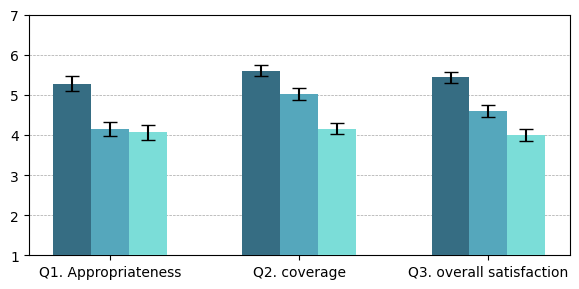

In [ ]:
def plot_combined_question_data():
    dp_means, threshold_means, random_means = [], [], []
    dp_sems, threshold_sems, random_sems = [], [], []

    for i in range(1, 4):
        dp, threshold, random = calculate_individual_averages(json_data_list, i)
        dp_means.append(dp)
        threshold_means.append(threshold)
        random_means.append(random)
        
        # # 표준 오차 계산 (SEM = 표준편차 / sqrt(샘플 수))
        # n = len(json_data_list)
        # dp_sems.append(dp_stats[1] / np.sqrt(n))
        # threshold_sems.append(threshold_stats[1] / np.sqrt(n))
        # random_sems.append(random_stats[1] / np.sqrt(n))
    def calculate_mean_and_sem(data):
        means = [np.mean(question) for question in data]
        sems = [np.std(question, ddof=1) / np.sqrt(len(question)) for question in data]
        return means, sems

    dp_avg, dp_sem = calculate_mean_and_sem(dp_means)
    threshold_avg, threshold_sem = calculate_mean_and_sem(threshold_means)
    random_avg, random_sem = calculate_mean_and_sem(random_means)
    
        # 그래프 생성
    labels = ['Q1. Appropriateness', 'Q2. coverage', 'Q3. overall satisfaction']
    x = np.arange(len(labels))
    width = 0.2
    fig, ax = plt.subplots(figsize=(6, 3))
    
    # grid 설정
    ax.set_ylim(1, 7)
    ax.grid(True, axis='y', color='gray', linestyle='--', linewidth=0.5, alpha=0.7, zorder=0)
    
    # 각각의 막대 그래프 (오차 막대 포함)
    ax.bar(x - width, dp_avg, width, yerr=dp_sem, capsize=5, color='#366D83', label='DP', zorder=3)
    ax.bar(x, threshold_avg, width, yerr=threshold_sem, capsize=5, color='#55A7BC', label='Threshold', zorder=3)
    ax.bar(x + width, random_avg, width, yerr=random_sem, capsize=5, color='#7BDDD8', label='Random', zorder=3)
    print(dp_avg, threshold_avg, random_avg)
    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    # ax.legend()
    
    plt.tight_layout()
    plt.show()


# 그래프 그리기
plot_combined_question_data()


In [10]:

# 데이터 준비
averaged_data = calculate_average_scores(json_data_list)

# 각 질문에 대해 프리드만 검정 수행 후 Wilcoxon 사후 검정
# 각 질문에 대해 프리드만 검정 수행 후 Wilcoxon 사후 검정
for question in ['Q1', 'Q2', 'Q3']:
    statistic, p_value = perform_friedman_test(averaged_data, question)
    
    print(f"\n{question}:")
    print(f"Friedman statistic: {statistic}")
    print(f"Friedman p-value: {p_value}")
    
    if p_value < 0.05:
        print("Significant difference found. Performing Wilcoxon signed-rank tests:")
        (z_dp_threshold, p_dp_threshold), (z_dp_random, p_dp_random), (z_threshold_random, p_threshold_random) = perform_wilcoxon_tests(averaged_data, question)
        
        print(f"DP vs Threshold: z = {z_dp_threshold:.4f}, p = {p_dp_threshold:.10f}")
        print(f"DP vs Random: z = {z_dp_random:.4f}, p = {p_dp_random:.10f}")
        print(f"Threshold vs Random: z = {z_threshold_random:.4f}, p = {p_threshold_random:.10f}")
        
        # plot_p_value_matrix([p_dp_threshold, p_dp_random, p_threshold_random], question)
    else:
        print("No significant difference found, post-hoc analysis not performed")


Q1:
Friedman statistic: 38.991150442477846
Friedman p-value: 3.413337718664741e-09
Significant difference found. Performing Wilcoxon signed-rank tests:
DP vs Threshold: z = 4.0000, p = 0.0000115828
DP vs Random: z = 0.0000, p = 0.0000109962
Threshold vs Random: z = 163.0000, p = 0.5319343136

Q2:
Friedman statistic: 42.939130434782584
Friedman p-value: 4.741178400687421e-10
Significant difference found. Performing Wilcoxon signed-rank tests:
DP vs Threshold: z = 19.5000, p = 0.0001163834
DP vs Random: z = 0.0000, p = 0.0000000056
Threshold vs Random: z = 21.0000, p = 0.0000016652

Q3:
Friedman statistic: 40.92173913043475
Friedman p-value: 1.3000416101059152e-09
Significant difference found. Performing Wilcoxon signed-rank tests:
DP vs Threshold: z = 14.0000, p = 0.0000803130
DP vs Random: z = 11.5000, p = 0.0000003912
Threshold vs Random: z = 75.0000, p = 0.0020317813


/source/ms/env/highlight/lib/python3.8/site-packages/scipy/stats/_morestats.py:3414: UserWarning: Exact p-value calculation does not work if there are zeros. Switching to normal approximation.
  warnings.warn("Exact p-value calculation does not work if there are "


In [11]:
import pandas as pd
import numpy as np
from scipy import stats
import statsmodels.api as sm
from statsmodels.formula.api import mixedlm

def prepare_data_for_mixed_model(json_data_list):
    data = []
    for person in json_data_list:
        for dataset in ['A', 'B', 'D', 'E', 'F']:
            for q in ['Q1', 'Q2', 'Q3']:
                for method in ['DP', 'Threshold', 'Random']:
                    data.append({
                        'name': person['name'],
                        'dataset': dataset,
                        'question': q,
                        'method': method,
                        'score': person['question'][dataset][q][method]
                    })
    return pd.DataFrame(data)

# 데이터 준비
df = prepare_data_for_mixed_model(json_data_list)

# 선형혼합모형 적용
model = mixedlm("score ~ C(method) + C(question) + C(dataset)", 
                data=df, 
                groups=df["name"])
results = model.fit()

print(results.summary())

# 사후 분석 (필요한 경우)
from statsmodels.stats.multicomp import pairwise_tukeyhsd

tukey_results = pairwise_tukeyhsd(df['score'], df['method'])
print(tukey_results)

              Mixed Linear Model Regression Results
Model:                MixedLM    Dependent Variable:    score     
No. Observations:     1350       Method:                REML      
No. Groups:           30         Scale:                 1.5180    
Min. group size:      45         Log-Likelihood:        -2246.0036
Max. group size:      45         Converged:             Yes       
Mean group size:      45.0                                        
------------------------------------------------------------------
                       Coef.  Std.Err.    z    P>|z| [0.025 0.975]
------------------------------------------------------------------
Intercept               4.844    0.157  30.828 0.000  4.536  5.152
C(method)[T.Random]    -1.364    0.082 -16.611 0.000 -1.525 -1.203
C(method)[T.Threshold] -0.844    0.082 -10.281 0.000 -1.005 -0.683
C(question)[T.Q2]       0.431    0.082   5.249 0.000  0.270  0.592
C(question)[T.Q3]       0.180    0.082   2.191 0.028  0.019  0.341
C(dataset)